# 03 · Benchmark methods and accuracy measures

Supports **Sections 5.3, 6.4 and 7.1** of the thesis. Seven classical methods forecast the 7 days after each
forecast origin for all 30,490 item-store series. They are the reference for the XGBoost models (IP1).

| Method | Forecast | Reference |
|---|---|---|
| Naive | last observed value | |
| Seasonal naive | last observed week, repeated | |
| Mean | mean over the active period (from the first sale) | |
| Croston | SES of the non-zero sizes / SES of the intervals between them | Croston (1972) |
| SBA | Croston × (1 − α/2), bias-corrected | Syntetos & Boylan (2005) |
| TSB | SES of the size × SES of the demand probability, updated every day | Teunter, Syntetos & Babai (2011) |
| ADIDA | SES on sums over buckets of ADI days, spread evenly | Nikolopoulos et al. (2011) |

All smoothing constants are fixed at α = β = 0.1. The methods are in `src/benchmarks.py` and the measures in
`src/metrics.py`.

**Protocol.** The validation window `d_1914`–`d_1941` is forecast 7 days at a time from 4 weekly origins
(`d_1913`, `d_1920`, `d_1927`, `d_1934`); every method is recomputed from the sales up to each origin. The
test window `d_1942`–`d_1969` is forecast in the same way in the final evaluation (notebook 06), because its
later origins need the test sales, which stay sealed until then.

**Measures.**
- **RMSSE**: root mean squared error divided by the in-sample one-step naive error of the series, from its first sale.
- **WRMSSE**: the M5 measure, computed here on the 28 days of the rolling 7-day forecasts: the RMSSE of all 42,840 series of the 12 hierarchy levels, weighted by dollar
  sales in the 28 days before the origin, with the 12 levels counting equally.
- **MASE**: the same scaling with absolute errors.
- **sME**: mean error on the MASE scale; negative means the forecast is too low on average.
- **Above / below**: shares of days on which the forecast is above or below the actual sales.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import benchmarks as B
import features as F
import m5_data as m5
import metrics as M
from plot_style import ACCENT, CONTEXT, INK_SECONDARY, SERIES, apply_style, label_line_end, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
RESULTS = ROOT / "results" / "benchmarks"
RESULTS.mkdir(parents=True, exist_ok=True)
FORECASTS = m5.PROCESSED_DIR / "forecasts"
FORECASTS.mkdir(parents=True, exist_ok=True)

NAMES = {"naive": "Naive", "snaive": "Seasonal naive", "mean": "Mean", "croston": "Croston", "sba": "SBA",
         "tsb": "TSB", "adida": "ADIDA"}
LEVEL_NAMES = {1: "Total", 2: "State", 3: "Store", 4: "Category", 5: "Department", 6: "State × category",
               7: "State × department", 8: "Store × category", 9: "Store × department", 10: "Item",
               11: "Item × state", 12: "Item × store"}

## 1. Check of the WRMSSE weights

The weights computed by `src/metrics.py` from the Kaggle files are compared with the official weight files
of the M5 competition (Nixtla mirror), for both forecast origins.

In [2]:
rows = []
evaluators = {}
for origin, file in [(m5.TRAIN_END, "weights_validation.csv"), (m5.VALID_END, "weights_evaluation.csv")]:
    actual = (m5.TRAIN_END + 1, m5.VALID_END) if origin == m5.TRAIN_END else None
    ev = M.Evaluator.for_origin(origin, actual)
    evaluators[origin] = ev
    ref = (pd.read_csv(m5.NIXTLA_DIR / file)
           .assign(level=lambda d: d["Level_id"].str[5:].astype(int))
           .rename(columns={"Agg_Level_1": "agg_1", "Agg_Level_2": "agg_2"}))
    both = ev.weights_table().merge(ref[["level", "agg_1", "agg_2", "weight"]], on=["level", "agg_1", "agg_2"],
                                    how="outer", suffixes=("", "_official"), indicator=True)
    rows.append({"origin": f"d_{origin}", "series": len(both), "unmatched": int((both["_merge"] != "both").sum()),
                 "max relative difference": float((both.weight - both.weight_official).abs().div(both.weight_official).max()),
                 "series with a zero scale": int(sum((ev.scale[lvl] == 0).sum() for lvl in ev.scale))})
check = pd.DataFrame(rows).set_index("origin")
assert (check["unmatched"] == 0).all() and (check["max relative difference"] < 1e-5).all()
check.style.format({"max relative difference": "{:.1e}"})

,series,unmatched,max relative difference,series with a zero scale
origin,,,,
d_1913,42840,0,1.9e-06,0
d_1941,42840,0,2.2e-06,0


The weights agree with the official ones for all 42,840 series; the remaining differences are the rounding of
the official files to eight significant digits.

## 2. Rolling forecasts of the validation window

In [3]:
panel = F.Panel.load(m5.PROCESSED_DIR / "panel")
forecasts = {"valid": B.forecast_rolling(panel.y, m5.TRAIN_END, m5.EVAL_WEEKS)}
np.savez(FORECASTS / "benchmarks.npz", **{f"valid_{m}": f for m, f in forecasts["valid"].items()})
print(f"saved {len(B.METHODS)} methods x {len(panel.ids):,} series x {m5.EVAL_WEEKS} origins x {B.HORIZON} days "
      f"to {(FORECASTS / 'benchmarks.npz').relative_to(ROOT)}")

saved 7 methods x 30,490 series x 4 origins x 7 days to data\processed\forecasts\benchmarks.npz


## 3. Accuracy on the validation window

In [4]:
ev = evaluators[m5.TRAIN_END]
fc = forecasts["valid"]
by_level = pd.DataFrame({m: ev.wrmsse(f) for m, f in fc.items()}).T
bottom = {m: ev.bottom(f) for m, f in fc.items()}
summary = pd.DataFrame(
    {
        "WRMSSE": by_level["all"],
        "RMSSE mean": {m: b.rmsse.mean() for m, b in bottom.items()},
        "RMSSE median": {m: b.rmsse.median() for m, b in bottom.items()},
        "MASE": {m: b.mase.mean() for m, b in bottom.items()},
        "sME": {m: b.sme.mean() for m, b in bottom.items()},
        "above": {m: b.above.mean() for m, b in bottom.items()},
        "below": {m: b.below.mean() for m, b in bottom.items()},
    }
).sort_values("WRMSSE")
summary.index = summary.index.map(NAMES)
summary.to_csv(RESULTS / "summary_valid.csv")
summary

,WRMSSE,RMSSE mean,RMSSE median,MASE,sME,above,below
Seasonal naive,0.924,1.011,0.959,1.225,-0.022,0.269,0.275
TSB,1.064,0.755,0.713,1.068,-0.018,0.677,0.323
ADIDA,1.066,0.753,0.705,1.053,-0.081,0.671,0.329
Croston,1.068,0.766,0.711,1.087,-0.038,0.672,0.328
SBA,1.094,0.765,0.709,1.073,-0.090,0.662,0.338
Mean,1.206,0.793,0.708,1.110,-0.183,0.653,0.347
Naive,1.753,1.043,0.959,1.330,0.196,0.321,0.245


RMSSE to sME are means over the 30,490 item-store series (level 12). WRMSSE covers all 12 levels.

In [5]:
levels = by_level.drop(columns="all")
levels.columns = levels.columns.astype(int)
levels.index = levels.index.map(NAMES)
levels.to_csv(RESULTS / "wrmsse_by_level_valid.csv")
levels.rename(columns=LEVEL_NAMES).T.style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold")

,Naive,Seasonal naive,Mean,Croston,SBA,TSB,ADIDA
Total,2.032,0.780,1.214,1.134,1.180,1.134,1.141
State,1.954,0.819,1.221,1.117,1.157,1.118,1.122
Store,1.875,0.857,1.327,1.108,1.147,1.110,1.114
Category,1.972,0.822,1.204,1.136,1.179,1.135,1.139
Department,2.014,0.894,1.278,1.193,1.227,1.187,1.190
State × category,1.890,0.867,1.211,1.120,1.155,1.120,1.121
State × department,1.905,0.925,1.256,1.156,1.183,1.150,1.150
Store × category,1.800,0.914,1.283,1.093,1.122,1.092,1.094
Store × department,1.783,0.969,1.287,1.106,1.125,1.101,1.101
Item,1.348,1.050,1.174,0.924,0.926,0.904,0.906


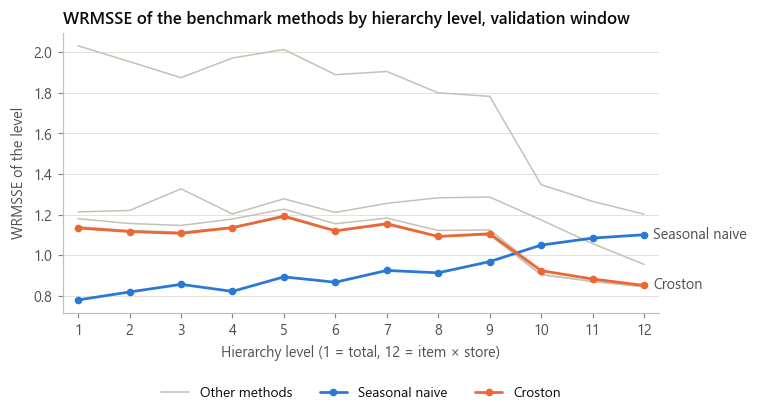

In [6]:
HIGHLIGHT = {"Seasonal naive": ACCENT, "Croston": SERIES[1]}
x = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(7, 3.3))
for m in levels.index.difference(HIGHLIGHT):
    ax.plot(x, levels.loc[m], color=CONTEXT, lw=1, zorder=1)
ax.plot([], [], color=CONTEXT, lw=1, label="Other methods")
for m, color in HIGHLIGHT.items():
    ax.plot(x, levels.loc[m], color=color, marker="o", ms=4, lw=1.8, label=m, zorder=3)
    label_line_end(ax, 12, levels.loc[m, 12], m)
ax.set_xticks(x)
ax.set_xlim(0.7, 12.3)
ax.set_title("WRMSSE of the benchmark methods by hierarchy level, validation window")
ax.set_xlabel("Hierarchy level (1 = total, 12 = item × store)")
ax.set_ylabel("WRMSSE of the level")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=3)
savefig(fig, "wrmsse_by_level_valid", subdir="benchmarks")
plt.show()

## 4. Accuracy by demand class

Mean RMSSE of the item-store series by Syntetos–Boylan–Croston class (from the training window, notebook 01).

In [7]:
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
assert (stats["id"].to_numpy() == panel.ids.to_numpy()).all()
rmsse = pd.DataFrame({NAMES[m]: b.rmsse for m, b in bottom.items()})
by_class = rmsse.groupby(stats["sbc_class"].to_numpy()).mean().T
by_class = by_class[["smooth", "erratic", "intermittent", "lumpy"]]
by_class.loc["series"] = stats["sbc_class"].value_counts()[by_class.columns]
by_class.to_csv(RESULTS / "rmsse_by_class_valid.csv")
by_class.style.format("{:.3f}").format("{:,.0f}", subset=pd.IndexSlice["series", :]).highlight_min(
    axis=0, subset=pd.IndexSlice[list(NAMES.values()), :], props="font-weight: bold")

,smooth,erratic,intermittent,lumpy
Naive,1.053,0.935,1.066,0.966
Seasonal naive,0.948,0.869,1.039,0.945
Mean,0.816,0.845,0.794,0.770
Croston,0.746,0.723,0.779,0.729
SBA,0.744,0.721,0.778,0.727
TSB,0.738,0.690,0.770,0.712
ADIDA,0.738,0.688,0.767,0.712
series,"1,921",874,"22,161","5,534"


In [8]:
rmsse.insert(0, "id", panel.ids.to_numpy())
rmsse.to_csv(RESULTS / "rmsse_valid.csv", index=False, float_format="%.5f")
print(f"per-series RMSSE saved to {(RESULTS / 'rmsse_valid.csv').relative_to(ROOT)} for the paired tests of notebook 06")

per-series RMSSE saved to results\benchmarks\rmsse_valid.csv for the paired tests of notebook 06


## Key findings

1. **Measures.** The WRMSSE weights computed from the Kaggle files agree with the official M5 weights for all
   42,840 series at both origins; no series has a zero scale. The scores are those of rolling 7-day forecasts
   over the 28 validation days, so they are not comparable with the official M5 scores or with the RMSSE@28 of
   Tsantilis et al. (2025), which belong to a single 28-day forecast.
2. **Seasonal naive is the best benchmark overall** (WRMSSE 0.924). It wins at the aggregated levels 1–9
   (0.78–0.97), where the weekly pattern dominates. The flat intermittent-demand methods score 1.09–1.23 there,
   because they forecast the same value for every day of the week.
3. **At the item levels (10–12) the order reverses.** Croston, SBA, TSB and ADIDA reach about 0.85 at level 12
   and a mean item-store RMSSE of 0.75–0.77, against 1.10 and 1.01 for the seasonal naive. No classical method is
   best across the whole hierarchy; a model that learns the weekly pattern from many series and still handles
   zeros could do well at both ends, which is what the global XGBoost is meant to test (IP1).
4. **The intermittent methods differ little.** Mean RMSSE: ADIDA 0.753, TSB 0.755, SBA 0.765, Croston 0.766.
   ADIDA is best in the erratic and intermittent classes and TSB in the smooth and lumpy classes, by at most 0.003
   over the other of the two.
5. **Bias.** The intermittent methods forecast slightly too low on average (sME −0.02 to −0.09), the historical
   mean more so (−0.18), and the naive method too high (+0.20). The flat methods are above the actual sales on
   about 67% of the days, because they forecast a positive amount on days without sales.
6. **One week is not enough.** On the first validation week alone the seasonal naive scored a WRMSSE of 0.571;
   over the four weeks it scores 0.924. The scores of a single week depend strongly on that week, which is why
   the evaluation uses four origins.
7. **Test window.** It is forecast in the same way in the final evaluation; its sales are not loaded here.